# Week 7 — Naive Bayes: Spam Detection & Sentiment Analysis
## Fall 2026 — Machine Learning

## Student Information
**Name:** Abdul Wali  
**Student ID:** 023-24-0174  
**Section:** F  
**GitHub:** AWS9760   
**Datasets:** SMS Spam Collection; Twitter US Airline Sentiment  
**Dataset Sources:**
- Task A: Kaggle — https://www.kaggle.com/datasets/uciml/sms-spam-collection-dataset
- Task B: Kaggle — https://www.kaggle.com/datasets/crowdflower/twitter-airline-sentiment

**Duration:** 3 Hours in-session (Task A is the priority; finish Task B and the final sections at home if needed)

> This notebook is a **template**, not a tutorial. You already know Naive Bayes theory. Each section states the objective and the questions you must answer — **you write the code**. Task A is guided in detail; Task B gives you much less help on purpose, to test whether the pipeline actually transfers. Every table, plot, and metric needs a short written observation.
>
> Submit **only this one notebook**. Keep every Markdown heading below — they are used for grading. Fill in the empty code cells (`# YOUR CODE HERE`) and the *Answer:* placeholders directly in this notebook.

---

## Setup

Import what you'll need. Add any other scikit-learn imports as you go.

In [1]:
import re
import glob
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, cross_validate, StratifiedKFold
from sklearn.pipeline import make_pipeline
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, ConfusionMatrixDisplay, classification_report)

warnings.filterwarnings("ignore")
RANDOM_STATE = 42                      # same seed everywhere so the results can be reproduced
pd.set_option("display.max_colwidth", 100)


def find_file(name):
    """Look for a dataset file in the working folder, Colab's /content and Kaggle's /kaggle/input."""
    for pattern in [name, f"/content/{name}", f"/content/**/{name}", f"/kaggle/input/**/{name}"]:
        hits = glob.glob(pattern, recursive=True)
        if hits:
            return hits[0]
    raise FileNotFoundError(f"{name} not found - upload it to the Colab Files panel "
                            f"(or attach the dataset to your Kaggle notebook).")

---

## 1. Problem Definition & Dataset Exploration

*Concepts/functions you may find useful:* `pd.read_csv()`, `df.shape`, `df.head()`, `df['label'].value_counts()`

**Tasks**
1. Load both datasets (`spam.csv` for Task A, `Tweets.csv` for Task B). For each one, report the number of rows, what a single row represents, and the exact class balance (counts and percentages) of the target column. Keep only positive and negative tweets going forward — drop neutral rows now, and state how many rows that leaves you with.
2. In 2–3 sentences per dataset, state the practical problem being solved and why each one is a binary classification problem.

In [2]:
# Task 1 - load spam.csv, inspect shape/head/class balance
spam_path = find_file("spam.csv")
spam_raw = pd.read_csv(spam_path, encoding="latin-1")      # the file is not valid UTF-8, so latin-1 is needed
print("Loaded from:", spam_path)
print("Raw shape:", spam_raw.shape)
print("\nNon-null values per column (the three 'Unnamed' columns are almost empty leftovers):")
print(spam_raw.notna().sum().to_string())

# keep only the label (v1) and the message text (v2)
spam = spam_raw[["v1", "v2"]].rename(columns={"v1": "label", "v2": "message"})
print("\nShape after keeping label + message:", spam.shape)
display(spam.head())

spam_counts = spam["label"].value_counts()
display(pd.DataFrame({"count": spam_counts, "percent": (spam_counts / len(spam) * 100).round(2)}))
print("Exact duplicate messages in the file:", spam["message"].duplicated().sum())

Loaded from: spam.csv
Raw shape: (5572, 5)

Non-null values per column (the three 'Unnamed' columns are almost empty leftovers):
v1            5572
v2            5572
Unnamed: 2      50
Unnamed: 3      12
Unnamed: 4       6

Shape after keeping label + message: (5572, 2)


,label,message
0,ham,"Go until jurong point, crazy.. Available only in bugis n great world la e buffet... Cine there got amore wat..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup final tkts 21st May 2005. Text FA to 87121 to receive entry question(std txt rate)T&C's apply 08452810075over18's
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives around here though"


,count,percent
label,,
ham,4825,86.59
spam,747,13.41


Exact duplicate messages in the file: 403


In [3]:
# Task 1 (continued) - load Tweets.csv, drop neutral, inspect shape/head/class balance
tweets_path = find_file("Tweets.csv")
tweets_raw = pd.read_csv(tweets_path)
print("Loaded from:", tweets_path)
print("Raw shape:", tweets_raw.shape)

all_counts = tweets_raw["airline_sentiment"].value_counts()
print("\nClass balance BEFORE dropping neutral tweets:")
display(pd.DataFrame({"count": all_counts, "percent": (all_counts / len(tweets_raw) * 100).round(2)}))

# keep only positive and negative tweets (and the columns we need)
tweets = (tweets_raw.loc[tweets_raw["airline_sentiment"] != "neutral", ["airline", "airline_sentiment", "text"]]
          .reset_index(drop=True))
print("Rows after dropping neutral tweets:", len(tweets), f"(dropped {len(tweets_raw) - len(tweets)})")

tweet_counts = tweets["airline_sentiment"].value_counts()
print("\nClass balance AFTER dropping neutral tweets:")
display(pd.DataFrame({"count": tweet_counts, "percent": (tweet_counts / len(tweets) * 100).round(2)}))
display(tweets.head())

Loaded from: Tweets.csv
Raw shape: (14640, 15)

Class balance BEFORE dropping neutral tweets:


,count,percent
airline_sentiment,,
negative,9178,62.69
neutral,3099,21.17
positive,2363,16.14


Rows after dropping neutral tweets: 11541 (dropped 3099)

Class balance AFTER dropping neutral tweets:


,count,percent
airline_sentiment,,
negative,9178,79.53
positive,2363,20.47


,airline,airline_sentiment,text
0,Virgin America,positive,@VirginAmerica plus you've added commercials to the experience... tacky.
1,Virgin America,negative,"@VirginAmerica it's really aggressive to blast obnoxious ""entertainment"" in your guests' faces &amp; they have little recourse"
2,Virgin America,negative,@VirginAmerica and it's a really big bad thing about it
3,Virgin America,negative,@VirginAmerica seriously would pay $30 a flight for seats that didn't have this playing.\nit's really the only bad thing about flying VA
4,Virgin America,positive,"@VirginAmerica yes, nearly every time I fly VX this “ear worm” won’t go away :)"


**Observations (Task 1):**
- **Task A:** `spam.csv` has 5,572 rows; one row is one SMS message with its label (`ham` or `spam`) and the message text. Exact class balance: ham 4,825 (86.59%) and spam 747 (13.41%). The three `Unnamed` columns are almost empty leftovers and were dropped, and the file contains 403 exact duplicate messages (kept, see the caveat in Section 3).
- **Task B:** `Tweets.csv` has 14,640 rows and 15 columns; one row is one tweet about a US airline with its sentiment label. Before filtering: negative 9,178 (62.69%), neutral 3,099 (21.17%), positive 2,363 (16.14%). After dropping the 3,099 neutral tweets, **11,541 rows** remain: negative 9,178 (79.53%) and positive 2,363 (20.47%).

**Answer 2 (Task A — spam):**
The practical problem is an SMS spam filter: for every incoming text message the phone (or the operator) must decide, from the words alone, whether to deliver it normally or move it to a spam folder. Each message has exactly one of two mutually exclusive labels, ham (0) or spam (1), so it is a binary classification problem. The classes are imbalanced (only 13.4% spam), so a filter that calls everything ham would already be 86.6% accurate while catching no spam at all, which is why precision, recall and F1 on the spam class matter more than accuracy.

**Answer 2 (Task B — sentiment):**
The practical problem is monitoring customer sentiment: an airline receives thousands of public tweets and wants to separate unhappy customers (who need a reply or a fix) from happy ones automatically, instead of reading everything by hand. After the neutral tweets are removed, every tweet is either negative (0) or positive (1), so it is a binary classification problem, and I treat *positive* as the class of interest (1). The data is imbalanced as well (79.5% negative), so an "always negative" model would score about 80% accuracy without understanding anything, and the positive-class precision, recall and F1 are the honest numbers.


---

## 2. Task A: Text Cleaning & Vectorization (Spam)

*Concepts/functions you may find useful:* `text.str.lower()`, `CountVectorizer` / `TfidfVectorizer`, `vectorizer.fit_transform(X_train)`, `vectorizer.transform(X_test)`, `vectorizer.get_feature_names_out()`

**Tasks**
3. Lightly clean the message text (lowercase at minimum). Keep this simple.
4. Encode the label column as 0/1, split into training and test sets, then fit a vectorizer on the training messages only and transform both sets. Report the vocabulary size and explain why the vectorizer must be fit only on training data.

In [4]:
# Task 3 - clean text (kept deliberately simple)
def clean_sms(text):
    text = text.lower()                          # lowercase
    text = re.sub(r"[^a-z0-9\s]", " ", text)      # punctuation / symbols -> space (digits are kept: '150p', '18', '1000' matter)
    return re.sub(r"\s+", " ", text).strip()      # collapse repeated whitespace


spam["clean"] = spam["message"].apply(clean_sms)
display(spam[["message", "clean"]].iloc[[2, 5, 12]])

,message,clean
2,Free entry in 2 a wkly comp to win FA Cup final tkts 21st May 2005. Text FA to 87121 to receive entry question(std txt rate)T&C's apply 08452810075over18's,free entry in 2 a wkly comp to win fa cup final tkts 21st may 2005 text fa to 87121 to receive entry question std txt rate t c s apply 08452810075over18 s
5,"FreeMsg Hey there darling it's been 3 week's now and no word back! I'd like some fun you up for it still? Tb ok! XxX std chgs to send, å£1.50 to rcv",freemsg hey there darling it s been 3 week s now and no word back i d like some fun you up for it still tb ok xxx std chgs to send 1 50 to rcv
12,"URGENT! You have won a 1 week FREE membership in our å£100,000 Prize Jackpot! Txt the word: CLAIM to No: 81010 T&C www.dbuk.net LCCLTD POBOX 4403LDNW1A7RW18",urgent you have won a 1 week free membership in our 100 000 prize jackpot txt the word claim to no 81010 t c www dbuk net lccltd pobox 4403ldnw1a7rw18


In [5]:
# Task 4 - encode labels, split, fit vectorizer on train only, transform both sets
y = (spam["label"] == "spam").astype(int)         # spam = 1 (the class we want to catch), ham = 0

X_train_txt, X_test_txt, y_train, y_test = train_test_split(
    spam["clean"], y, test_size=0.2, random_state=RANDOM_STATE, stratify=y)
print("Train messages:", len(X_train_txt), "| Test messages:", len(X_test_txt))
print(f"Spam share  train: {y_train.mean():.2%}  test: {y_test.mean():.2%}")

vectorizer = CountVectorizer()
X_train_vec = vectorizer.fit_transform(X_train_txt)   # the vocabulary is learned from TRAIN only
X_test_vec = vectorizer.transform(X_test_txt)         # test messages are only mapped onto that vocabulary
vocab_size = len(vectorizer.vocabulary_)
print("\nTrain matrix:", X_train_vec.shape, "| Test matrix:", X_test_vec.shape)
print("Vocabulary size (training messages only):", vocab_size)

# words in the test messages that the model has never seen
analyzer = vectorizer.build_analyzer()
test_words = {w for m in X_test_txt for w in analyzer(m)}
unseen_words = test_words - set(vectorizer.vocabulary_)
print(f"Distinct test-message words missing from the training vocabulary: {len(unseen_words)} of {len(test_words)}")

Train messages: 4457 | Test messages: 1115
Spam share  train: 13.42%  test: 13.36%

Train matrix: (4457, 7658) | Test matrix: (1115, 7658)
Vocabulary size (training messages only): 7658
Distinct test-message words missing from the training vocabulary: 964 of 3534


**Answer 4 (why fit on training data only):**
The test set has to play the role of messages the filter has never seen. If the vectorizer were fitted on all messages, the vocabulary (and, for TF-IDF, the IDF weights) would be computed partly from test messages, so information from the test set would leak into the features and the test scores would become optimistic. With plain word counts the effect is small, but the habit matters, because a deployed filter cannot refit on messages that have not arrived yet. The split also shows why this is realistic: 964 of the 3,534 distinct words in my test messages (27%) are not in the training vocabulary and are simply ignored at prediction time, exactly as brand-new words would be in real use. The vocabulary learned from the training messages has **7,658 words**.


In [6]:
# Which vectorizer for Task A? 5-fold cross-validation on the TRAINING set only (the test set stays untouched).
# Using a pipeline means the vectorizer is re-fitted inside every fold, so no fold ever sees its own validation messages.
cv5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
candidates_a = {
    "CountVectorizer + NB": make_pipeline(CountVectorizer(), MultinomialNB()),
    "TfidfVectorizer + NB": make_pipeline(TfidfVectorizer(), MultinomialNB()),
    "TfidfVectorizer + NB (fit_prior=False)": make_pipeline(TfidfVectorizer(), MultinomialNB(fit_prior=False)),
}
rows = []
for name, pipe in candidates_a.items():
    res = cross_validate(pipe, X_train_txt, y_train, cv=cv5, scoring=["precision", "recall", "f1"])
    rows.append({"setup": name,
                 "CV precision": res["test_precision"].mean().round(4),
                 "CV recall": res["test_recall"].mean().round(4),
                 "CV F1": res["test_f1"].mean().round(4),
                 "F1 std": res["test_f1"].std().round(4)})
cv_vectorizer_a = pd.DataFrame(rows)
display(cv_vectorizer_a)

,setup,CV precision,CV recall,CV F1,F1 std
0,CountVectorizer + NB,0.9811,0.9297,0.9545,0.0059
1,TfidfVectorizer + NB,1.0000,0.6705,0.8022,0.0252
2,TfidfVectorizer + NB (fit_prior=False),0.9413,0.8946,0.9170,0.0096


**Observation (vectorizer choice):** I used `CountVectorizer` because Multinomial Naive Bayes models word *counts*, and it clearly won the cross-validation on the training set (F1 0.955 against 0.802 for TF-IDF). TF-IDF was perfectly precise but its recall fell to 0.670: its weights are small fractions, so each word contributes much less evidence compared with the fixed class prior (only about 13% of the messages are spam) and borderline spam is pushed to "ham". Switching the prior off (`fit_prior=False`) raises the TF-IDF recall to 0.895 (F1 0.917), which supports this explanation, but it still does not beat plain counts.


---

## 3. Task A: Naive Bayes Model & Evaluation (Spam)

*Concepts/functions you may find useful:* `MultinomialNB()`, `.fit()`, `.predict()`, `accuracy_score`, `precision_score`, `recall_score`, `f1_score`, `confusion_matrix`

**Tasks**
5. Train a `MultinomialNB` model on the vectorized training data. Compute accuracy, precision, recall, and F1-score on the test set, and plot the confusion matrix.
6. Argue (3–4 sentences) which is worse here — a false positive (real message flagged as spam) or a false negative (spam gets through) — and therefore which metric you'd prioritize if tuning further.

Accuracy : 0.9839
Precision: 0.9645
Recall   : 0.9128
F1-score : 0.9379

Confusion matrix: TN=961  FP=5  FN=13  TP=136
Baseline: always predicting 'ham' would score 0.8664 accuracy but catch 0 spam messages


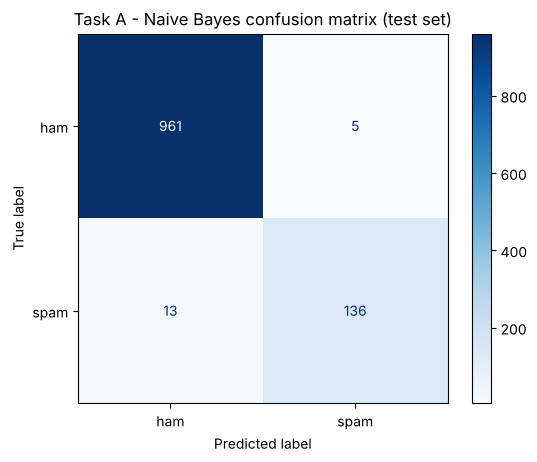

In [7]:
# Task 5 - train MultinomialNB, compute metrics, plot confusion matrix
nb = MultinomialNB()                   # alpha = 1.0 -> Laplace smoothing; class priors come from the training labels
nb.fit(X_train_vec, y_train)
y_pred = nb.predict(X_test_vec)

acc_a = accuracy_score(y_test, y_pred)
prec_a = precision_score(y_test, y_pred)        # spam (1) is the positive class
rec_a = recall_score(y_test, y_pred)
f1_a = f1_score(y_test, y_pred)
print(f"Accuracy : {acc_a:.4f}")
print(f"Precision: {prec_a:.4f}")
print(f"Recall   : {rec_a:.4f}")
print(f"F1-score : {f1_a:.4f}")

cm_a = confusion_matrix(y_test, y_pred)
tn_a, fp_a, fn_a, tp_a = cm_a.ravel()
print(f"\nConfusion matrix: TN={tn_a}  FP={fp_a}  FN={fn_a}  TP={tp_a}")
baseline_a = 1 - y_test.mean()
print(f"Baseline: always predicting 'ham' would score {baseline_a:.4f} accuracy but catch 0 spam messages")

ConfusionMatrixDisplay(cm_a, display_labels=["ham", "spam"]).plot(cmap="Blues", values_format="d")
plt.title("Task A - Naive Bayes confusion matrix (test set)")
plt.show()

**Task 5 — Spam Model Metrics**

| Metric | Value |
|---|---|
| Accuracy | 0.9839 |
| Precision | 0.9645 |
| Recall | 0.9128 |
| F1-score | 0.9379 |

(Test set: 1,115 messages, 149 of them spam; spam is the positive class.)

**Observation:** The model caught 136 of the 149 spam messages and missed 13, and it wrongly flagged 5 of the 966 real messages. Accuracy (98.39%) looks excellent, but always predicting "ham" already gives 86.64%, so precision (0.965: when it says spam it is right about 96 times in 100) and recall (0.913) are the more informative numbers. Precision is higher than recall, so the model is cautious: it prefers to let a doubtful message through rather than block it. **Caveat:** 134 of the test messages (12.0%) also occur, after cleaning, in the training set, so the scores are slightly optimistic; on the remaining messages F1 is 0.924 (details in the cell below).

**Answer 6:**
A false positive is worse here: a real message that lands in the spam folder (a one-time code, a delivery notice, a message from a friend) may never be read and makes users stop trusting the filter, whereas a false negative is one visible spam message that can be deleted in a second. I would therefore prioritize **precision**, meaning keep the false positives near zero, and only then try to raise recall, for example by blocking a message only when its spam probability is above a cut-off higher than 0.5, chosen with cross-validation on the training data. The current model already leans in this direction, with 5 false positives (0.52% of the real messages) against 13 missed spam messages, and its false positives were all short or ambiguous texts such as "Anytime..." and "Waiting for your call.". Recall cannot be ignored completely, because a filter that lets too much spam through is not useful either, so I would report F1 next to precision.


In [8]:
# What do the errors look like? (supporting evidence for Answer 6)
test_msgs = spam.loc[X_test_txt.index, "message"]
p_spam = nb.predict_proba(X_test_vec)[:, 1]

fp_idx = np.where((y_test.values == 0) & (y_pred == 1))[0]
fn_idx = np.where((y_test.values == 1) & (y_pred == 0))[0]

print(f"False positives (real messages flagged as spam): {len(fp_idx)}")
for i in fp_idx:
    print(f"  P(spam)={p_spam[i]:.2f} | {test_msgs.iloc[i][:100]}")

print(f"\nFalse negatives (spam that got through): {len(fn_idx)}  - the 5 closest to being caught:")
for i in fn_idx[np.argsort(-p_spam[fn_idx])][:5]:
    print(f"  P(spam)={p_spam[i]:.2f} | {test_msgs.iloc[i][:100]}")

print(f"\nSpam messages that looked completely like normal chat (P(spam) < 0.01): {(p_spam[fn_idx] < 0.01).sum()} of {len(fn_idx)}")

# do test messages also appear (after cleaning) in the training set? Exact copies make the test slightly easier
dup_mask = X_test_txt.isin(set(X_train_txt)).values
n_dup_a = int(dup_mask.sum())
f1_unseen_a = f1_score(y_test[~dup_mask], y_pred[~dup_mask])
print(f"\nTest messages whose cleaned text also occurs in the training set: {n_dup_a} ({dup_mask.mean():.1%})")
print(f"F1 on the other {(~dup_mask).sum()} test messages only: {f1_unseen_a:.4f}  (all test messages: {f1_a:.4f})")

# how sure is the model when it is right / wrong?
conf_a = np.maximum(p_spam, 1 - p_spam)
sure_a = conf_a > 0.99
wrong_a = y_pred != y_test.values
print(f"Messages predicted with more than 99% confidence: {sure_a.mean():.1%}  (accuracy among them: {(~wrong_a)[sure_a].mean():.1%})")
print(f"Errors made with more than 99% confidence: {(wrong_a & sure_a).sum()} of {wrong_a.sum()}")

False positives (real messages flagged as spam): 5
  P(spam)=0.52 | Anytime...
  P(spam)=0.64 | Waiting for your call.
  P(spam)=0.82 | Unlimited texts. Limited minutes.
  P(spam)=0.86 | Nokia phone is lovly..
  P(spam)=0.98 | We have sent JD for Customer Service cum Accounts Executive to ur mail id, For details contact us

False negatives (spam that got through): 13  - the 5 closest to being caught:
  P(spam)=0.42 | RCT' THNQ Adrian for U text. Rgds Vatian
  P(spam)=0.41 | Download as many ringtones as u like no restrictions, 1000s 2 choose. U can even send 2 yr buddys. T
  P(spam)=0.35 | Email AlertFrom: Jeri StewartSize: 2KBSubject: Low-cost prescripiton drvgsTo listen to email call 12
  P(spam)=0.22 | Hi babe its Jordan, how r u? Im home from abroad and lonely, text me back if u wanna chat xxSP visio
  P(spam)=0.14 | Latest News! Police station toilet stolen, cops have nothing to go on!

Spam messages that looked completely like normal chat (P(spam) < 0.01): 7 of 13

Test messages 

---

## 4. Task A: Word Interpretation (Spam)

*Concepts/functions you may find useful:* `model.feature_log_prob_`, `np.argsort(...)`

**Tasks**
7. Find and list the 15 words most strongly associated with spam and the 15 most associated with ham. Do these match your intuition?
8. Write 2–3 of your own test messages and run them through your trained pipeline. Do the predictions match what you expected?

15 words most associated with SPAM:


,word,log_ratio,in_spam_msgs,in_ham_msgs
0,claim,5.53,89,0
1,prize,5.20,60,0
2,150p,4.98,54,0
3,tone,4.83,33,0
4,18,4.71,41,0
5,cs,4.67,39,0
6,500,4.61,37,0
7,guaranteed,4.61,37,0
8,1000,4.50,33,0
9,uk,4.44,59,1


15 words most associated with HAM:


,word,log_ratio,in_spam_msgs,in_ham_msgs
0,gt,-4.59,0,195
1,lt,-4.57,0,193
2,he,-4.10,0,119
3,lor,-3.89,0,115
4,da,-3.89,0,115
5,she,-3.86,0,87
6,later,-3.79,0,113
7,ll,-3.34,2,211
8,doing,-3.30,0,71
9,say,-3.27,0,66


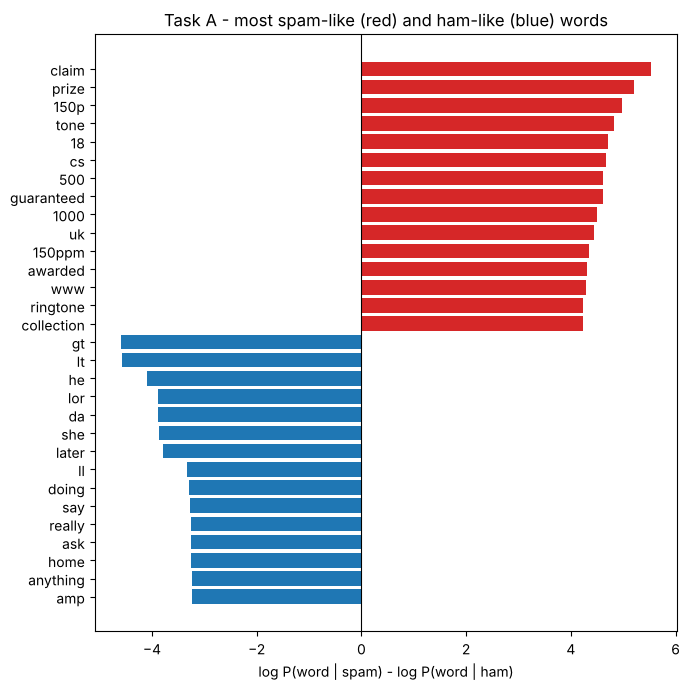

'free': log-ratio 2.22 -> about 9x more likely in spam (in 132 spam msgs but also 50 ham msgs)
Messages containing the escaped placeholder '&lt;#&gt;': 214 (spam among them: 0)
Example: Great! I hope you like your man well endowed. I am  &lt;#&gt;  inches...


In [9]:
# Task 7 - extract top spam words and top ham words from feature_log_prob_
words = vectorizer.get_feature_names_out()
# natural-log ratio P(word | spam) / P(word | ham) after Laplace smoothing: > 0 -> spam word, < 0 -> ham word
log_ratio = nb.feature_log_prob_[1] - nb.feature_log_prob_[0]
order = np.argsort(log_ratio)

# in how many training messages of each class does the word appear? (to make sure the ratio is not based on 1-2 messages)
spam_docs = np.asarray((X_train_vec[y_train.values == 1] > 0).sum(axis=0)).ravel()
ham_docs = np.asarray((X_train_vec[y_train.values == 0] > 0).sum(axis=0)).ravel()


def word_table(idx):
    return pd.DataFrame({"word": words[idx], "log_ratio": log_ratio[idx].round(2),
                         "in_spam_msgs": spam_docs[idx], "in_ham_msgs": ham_docs[idx]}).reset_index(drop=True)


top_spam = word_table(order[::-1][:15])
top_ham = word_table(order[:15])
print("15 words most associated with SPAM:")
display(top_spam)
print("15 words most associated with HAM:")
display(top_ham)

fig, ax = plt.subplots(figsize=(7, 7))
plot_df = pd.concat([top_ham.iloc[::-1], top_spam.iloc[::-1]])
ax.barh(plot_df["word"], plot_df["log_ratio"], color=["tab:blue"] * 15 + ["tab:red"] * 15)
ax.axvline(0, color="black", linewidth=0.8)
ax.set_xlabel("log P(word | spam) - log P(word | ham)")
ax.set_title("Task A - most spam-like (red) and ham-like (blue) words")
plt.tight_layout()
plt.show()

# two surprises worth checking
idx = {w: i for i, w in enumerate(words)}
print(f"'free': log-ratio {log_ratio[idx['free']]:.2f} -> about {np.exp(log_ratio[idx['free']]):.0f}x more likely in spam "
      f"(in {spam_docs[idx['free']]} spam msgs but also {ham_docs[idx['free']]} ham msgs)")
entity = spam["message"].str.contains("&lt;#&gt;", regex=False)
print(f"Messages containing the escaped placeholder '&lt;#&gt;': {entity.sum()} (spam among them: {(entity & (spam['label'] == 'spam')).sum()})")
print("Example:", spam.loc[entity, "message"].iloc[0])

**Answer 7:**
The spam list matches my intuition almost completely: *claim*, *prize*, *guaranteed* and *awarded* are the language of prize draws, *collection* comes from phrases like "cash await collection", *150p* and *150ppm* are premium-rate prices, *tone* and *ringtone* are ringtone offers, *18* is the "18+" age line, *500* and *1000* are cash amounts, *cs* comes from "T&Cs", and *www* and *uk* come from web addresses and UK services. These words occur in dozens of spam messages and almost never in ham (for example *claim* appears in 89 spam and 0 ham messages), so the ratios are not based on one or two lucky messages.

The ham list is less intuitive. It contains no "friendly" words but ordinary conversation: *he*, *she*, *later*, *doing*, *say*, *really*, *ask*, *home*, *anything* and chat particles such as *lor* and *da*, so the model has learned what spam does *not* sound like (spam talks about offers and prizes, not about people and plans). Three entries are not words at all: *gt*, *lt* and *amp* come from HTML-escaped text such as `&lt;#&gt;` (214 messages, none of them spam) and `&amp;`, which my simple cleaning turned into the "words" *lt*, *gt* and *amp*. Finally, *free*, which I expected at the top, has a log-ratio of only 2.22 (about 9 times more likely in spam) because it also appears in 50 ham messages (against 132 spam messages), so it is a useful clue but not a decisive one.


In [10]:
# Task 8 - test your own messages
my_messages = [
    ("WINNER!! You have been selected to receive a free prize. Call 09061234567 now to claim your cash reward!", "spam"),
    ("Hey, are we still meeting at the library at 5? Bring the notes for the ML lab.", "ham"),
    ("Free pizza at the cafeteria today at 1pm, come early before it finishes", "ham"),
    ("Congratulations! Your number has won a 1000 pound voucher. Text CLAIM to 80082 to collect", "spam"),
    ("Your parcel could not be delivered. Reply with your address to reschedule", "spam"),
    ("Dear customer, your bank account has been suspended. Verify your identity at secure-bank-login.com to restore access.", "spam"),
    ("Hi, it's Sarah from your gym. Your membership payment failed, please update your card details at gym-pay.net", "spam"),
]

# full pipeline: same cleaning -> same (train-fitted) vectorizer -> trained model
rows = []
for text, expected in my_messages:
    vec = vectorizer.transform([clean_sms(text)])
    p = nb.predict_proba(vec)[0, 1]
    rows.append({"message": text[:70] + ("..." if len(text) > 70 else ""), "I expected": expected,
                 "P(spam)": round(p, 3), "model says": "spam" if p >= 0.5 else "ham"})
my_results = pd.DataFrame(rows)
display(my_results)

# why is the 'Free pizza ...' message still ham? Add up the evidence word by word.
pizza_text = my_messages[2][0]
tokens = [w for w in analyzer(clean_sms(pizza_text)) if w in idx]
print("Word-by-word evidence (log-ratio, + = spam, - = ham) for:", pizza_text)
print("  " + ", ".join(f"{w} {log_ratio[idx[w]]:+.2f}" for w in tokens))
prior_lo = nb.class_log_prior_[1] - nb.class_log_prior_[0]
total_lo = prior_lo + sum(log_ratio[idx[w]] for w in tokens)
print(f"  prior {prior_lo:+.2f} + words {total_lo - prior_lo:+.2f} = log-odds {total_lo:+.2f} -> P(spam) = {1 / (1 + np.exp(-total_lo)):.4f}")
print("  ('cafeteria' is not in the training vocabulary and is ignored)")

,message,I expected,P(spam),model says
0,WINNER!! You have been selected to receive a free prize. Call 09061234...,spam,1.000,spam
1,"Hey, are we still meeting at the library at 5? Bring the notes for the...",ham,0.000,ham
2,"Free pizza at the cafeteria today at 1pm, come early before it finishe...",ham,0.000,ham
3,Congratulations! Your number has won a 1000 pound voucher. Text CLAIM ...,spam,1.000,spam
4,Your parcel could not be delivered. Reply with your address to resched...,spam,0.574,spam
5,"Dear customer, your bank account has been suspended. Verify your ident...",spam,1.000,spam
6,"Hi, it's Sarah from your gym. Your membership payment failed, please u...",spam,0.011,ham


Word-by-word evidence (log-ratio, + = spam, - = ham) for: Free pizza at the cafeteria today at 1pm, come early before it finishes
  free +2.22, pizza -1.10, at -1.80, the -0.71, today -0.64, at -1.80, 1pm +0.28, come -3.07, early -2.39, before -1.16, it -2.03, finishes -0.12
  prior -1.86 + words -12.33 = log-odds -14.20 -> P(spam) = 0.0000
  ('cafeteria' is not in the training vocabulary and is ignored)


**Answer 8:**
6 of my 7 messages were classified as I expected. The prize and voucher texts got P(spam) of about 1.00 and the library message about 0.00. "Free pizza at the cafeteria..." contains the spam-like word *free* but is still ham, because the word-by-word printout shows that *free* adds only +2.22 to the log-odds while words such as *come*, *at*, *early*, *before* and *it* each pull towards ham; all words together add -12.3, and with the negative class prior the final log-odds is -14.2. This is how Naive Bayes adds up the evidence of all words as if they were independent. The parcel text is classified as spam but only just (P = 0.57), and the "gym" message, a modern phishing-style text without any premium-rate vocabulary, was **missed** (P(spam) = 0.01). This matches the false negatives on the test set (spam written like ordinary chat) and shows a limit of the training data: it mostly contains premium-rate and prize scams (see the top spam words), so scam styles that are not in it are largely invisible to the model.


---

## 5. Task A: Kaggle Notebook Submission

Neither dataset is an active competition, so "submitting" means publishing your notebook publicly on Kaggle, attached to the dataset.

**Tasks**
9. Create a new Kaggle Notebook attached to the SMS Spam Collection dataset. Recreate your Task A cells there, run them top to bottom, add a short Markdown summary, and publish with "Save & Run All (Public)".
10. Record the public notebook URL below.

**Task A Kaggle Notebook URL:**
_(paste your published notebook link here)_

---

## 6. Task B: Text Cleaning & Vectorization (Sentiment)

Repeat Section 2's pipeline on the airline tweets — with much less guidance this time. Tweets contain @mentions, links, and hashtags that SMS messages didn't.

**Tasks**
11. Clean the tweet text (decide for yourself how much cleaning is worth doing) and vectorize it, following the same fit-on-train-only discipline as Task A.
12. Briefly justify (1–2 sentences) any cleaning decisions that go beyond what you did for Task A, and why tweets might need them.

In [11]:
# Task 11 - clean and vectorize the sentiment data (your own approach)
def clean_tweet(text, keep_mentions=False):
    text = text.replace("\u2019", "'").lower()                # curly apostrophes -> straight, lowercase
    text = re.sub(r"https?://\S+|www\.\S+", " ", text)         # links (t.co/... are random strings)
    if not keep_mentions:
        text = re.sub(r"@\w+", " ", text)                     # @airline mentions
    text = text.replace("#", " ")                              # keep the hashtag WORD, drop the '#'
    text = text.replace("can't", "cannot").replace("won't", "will not")
    text = re.sub(r"n't\b", " not", text)                     # don't -> do not, isn't -> is not ...
    text = re.sub(r"[^a-z0-9\s]", " ", text)                  # remaining punctuation / emojis
    return re.sub(r"\s+", " ", text).strip()                  # NOTE: stop words are NOT removed ('not', 'no' carry sentiment)


tweets["clean"] = tweets["text"].apply(clean_tweet)
display(tweets[["text", "clean"]].iloc[[3, 10, 24]])

y_tw = (tweets["airline_sentiment"] == "positive").astype(int)     # positive = 1 (the minority class)
Xtr_txt, Xte_txt, ytr_tw, yte_tw = train_test_split(
    tweets["clean"], y_tw, test_size=0.2, random_state=RANDOM_STATE, stratify=y_tw)
print("\nTrain tweets:", len(Xtr_txt), "| Test tweets:", len(Xte_txt))
print(f"Positive share  train: {ytr_tw.mean():.2%}  test: {yte_tw.mean():.2%}")

tw_vectorizer = CountVectorizer()
Xtr_tw = tw_vectorizer.fit_transform(Xtr_txt)      # fit on training tweets only
Xte_tw = tw_vectorizer.transform(Xte_txt)
vocab_size_tw = len(tw_vectorizer.vocabulary_)
print("Train matrix:", Xtr_tw.shape, "| Test matrix:", Xte_tw.shape)
print("Vocabulary size (training tweets only):", vocab_size_tw)

,text,clean
3,@VirginAmerica seriously would pay $30 a flight for seats that didn't have this playing.\nit's really the only bad thing about flying VA,seriously would pay 30 a flight for seats that did not have this playing it s really the only bad thing about flying va
10,@VirginAmerica Thanks!,thanks
24,"@VirginAmerica help, left expensive headphones on flight 89 IAD to LAX today. Seat 2A. No one answering L&amp;F number at LAX!",help left expensive headphones on flight 89 iad to lax today seat 2a no one answering l amp f number at lax



Train tweets: 9232 | Test tweets: 2309
Positive share  train: 20.47%  test: 20.49%
Train matrix: (9232, 10065) | Test matrix: (2309, 10065)
Vocabulary size (training tweets only): 10065


In [12]:
# Why this configuration? Alternatives compared with 5-fold cross-validation on the TRAINING tweets only
tweets["lower"] = tweets["text"].str.lower()                               # lowercase only (Task A style)
tweets["clean_mentions"] = tweets["text"].apply(clean_tweet, keep_mentions=True)

setups_b = [
    ("lowercase only      | counts | unigrams",       "lower",          lambda: make_pipeline(CountVectorizer(), MultinomialNB())),
    ("full cleaning       | counts | unigrams  <- used", "clean",       lambda: make_pipeline(CountVectorizer(), MultinomialNB())),
    ("keep @mentions      | counts | unigrams",       "clean_mentions", lambda: make_pipeline(CountVectorizer(), MultinomialNB())),
    ("full cleaning       | TF-IDF | unigrams",       "clean",          lambda: make_pipeline(TfidfVectorizer(), MultinomialNB())),
    ("full cleaning       | counts | uni+bigrams",    "clean",          lambda: make_pipeline(CountVectorizer(ngram_range=(1, 2)), MultinomialNB())),
    ("full cleaning       | TF-IDF | uni+bigrams",    "clean",          lambda: make_pipeline(TfidfVectorizer(ngram_range=(1, 2)), MultinomialNB())),
    ("TF-IDF unigrams, fit_prior=False",              "clean",          lambda: make_pipeline(TfidfVectorizer(), MultinomialNB(fit_prior=False))),
    ("counts uni+bigrams, fit_prior=False",           "clean",          lambda: make_pipeline(CountVectorizer(ngram_range=(1, 2)), MultinomialNB(fit_prior=False))),
]
rows = []
for name, col, make in setups_b:
    res = cross_validate(make(), tweets.loc[Xtr_txt.index, col], ytr_tw, cv=cv5, scoring=["recall", "f1"])
    rows.append({"setup": name, "CV recall (positive)": res["test_recall"].mean().round(4),
                 "CV F1 (positive)": res["test_f1"].mean().round(4), "F1 std": res["test_f1"].std().round(4)})
cv_setups_b = pd.DataFrame(rows)
display(cv_setups_b)

neg_share = tweets.groupby("airline")["airline_sentiment"].apply(lambda s: (s == "negative").mean()).round(3)
print("Share of negative tweets per airline (why @mentions leak information that is not sentiment):")
print(neg_share.to_string())

,setup,CV recall (positive),CV F1 (positive),F1 std
0,lowercase only | counts | unigrams,0.5905,0.7152,0.0222
1,full cleaning | counts | unigrams <- used,0.5862,0.7136,0.0201
2,keep @mentions | counts | unigrams,0.6011,0.7246,0.0163
3,full cleaning | TF-IDF | unigrams,0.1714,0.2923,0.0042
4,full cleaning | counts | uni+bigrams,0.4270,0.5937,0.0129
5,full cleaning | TF-IDF | uni+bigrams,0.1190,0.2125,0.0195
6,"TF-IDF unigrams, fit_prior=False",0.5101,0.6552,0.0171
7,"counts uni+bigrams, fit_prior=False",0.5021,0.6557,0.0129


Share of negative tweets per airline (why @mentions leak information that is not sentiment):
airline
American          0.854
Delta             0.637
Southwest         0.675
US Airways        0.894
United            0.843
Virgin America    0.544


**Observation (choice of configuration):** The cleaning choices hardly matter: lowercase only, full cleaning and keeping the @mentions are within one standard deviation of each other, so I chose the one I can justify on principle (full cleaning, see Answer 12). The vectorizer matters a great deal: plain word counts with unigrams are clearly best (F1 0.714), while TF-IDF (0.292) and bigrams (0.594) collapse because their recall on positive tweets drops from 0.59 to 0.17 and 0.43. The `fit_prior=False` rows show why: once the class prior (only about 20% of the tweets are positive) is switched off, TF-IDF recovers to 0.655 and the bigram model to 0.656. TF-IDF shrinks the evidence of every word and bigrams spread it over many rarer features, so in both cases the prior outweighs the evidence and borderline positive tweets are assigned to the majority class. The final Task B model therefore uses counts and unigrams.


**Answer 12:**
Tweets contain things SMS messages did not: links (random `t.co` strings), @mentions that only name the airline, hashtags and contractions, so I removed the links and @mentions, kept the hashtag words, and expanded *n't* to *not* without removing stop words, because negation words carry much of the sentiment in a bag-of-words model. I dropped the @mentions even though keeping them scored nominally higher in cross-validation (F1 0.725 against 0.714, a difference smaller than the fold-to-fold standard deviation of about 0.02), because a mention only tells the model *which airline* was addressed and the share of negative tweets runs from 54% (Virgin America) to 89% (US Airways), so it would learn airline reputation instead of the language of sentiment.


---

## 7. Task B: Naive Bayes Model & Evaluation (Sentiment)

**Tasks**
13. Train a `MultinomialNB` model on the vectorized tweet data. Compute accuracy, precision, recall, and F1-score, and plot the confusion matrix.
14. Compare these metrics to Task A's. Did Naive Bayes do better or worse on sentiment than on spam? Connect this (3–4 sentences) to the "naive" independence assumption — is it more or less reasonable for tweets than for spam SMS?

Accuracy : 0.9052
Precision: 0.9097
Recall   : 0.5962
F1-score : 0.7203

Confusion matrix: TN=1808  FP=28  FN=191  TP=282
Baseline: always predicting 'negative' would score 0.7951 accuracy but find 0 positive tweets

Per-class report:
              precision    recall  f1-score   support

    negative      0.904     0.985     0.943      1836
    positive      0.910     0.596     0.720       473

    accuracy                          0.905      2309
   macro avg      0.907     0.790     0.832      2309
weighted avg      0.906     0.905     0.897      2309



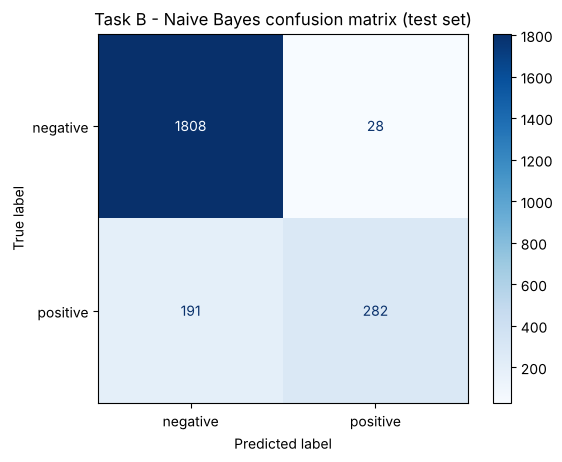

In [13]:
# Task 13 - train MultinomialNB, compute metrics, plot confusion matrix
nb_tw = MultinomialNB()
nb_tw.fit(Xtr_tw, ytr_tw)
pred_tw = nb_tw.predict(Xte_tw)

acc_b = accuracy_score(yte_tw, pred_tw)
prec_b = precision_score(yte_tw, pred_tw)       # positive sentiment (1) is the positive class
rec_b = recall_score(yte_tw, pred_tw)
f1_b = f1_score(yte_tw, pred_tw)
print(f"Accuracy : {acc_b:.4f}")
print(f"Precision: {prec_b:.4f}")
print(f"Recall   : {rec_b:.4f}")
print(f"F1-score : {f1_b:.4f}")

cm_b = confusion_matrix(yte_tw, pred_tw)
tn_b, fp_b, fn_b, tp_b = cm_b.ravel()
print(f"\nConfusion matrix: TN={tn_b}  FP={fp_b}  FN={fn_b}  TP={tp_b}")
baseline_b = 1 - yte_tw.mean()
print(f"Baseline: always predicting 'negative' would score {baseline_b:.4f} accuracy but find 0 positive tweets")
print("\nPer-class report:")
print(classification_report(yte_tw, pred_tw, target_names=["negative", "positive"], digits=3))

ConfusionMatrixDisplay(cm_b, display_labels=["negative", "positive"]).plot(cmap="Blues", values_format="d")
plt.title("Task B - Naive Bayes confusion matrix (test set)")
plt.show()

**Task 13 — Sentiment Model Metrics**

| Metric | Value |
|---|---|
| Accuracy | 0.9052 |
| Precision | 0.9097 |
| Recall | 0.5962 |
| F1-score | 0.7203 |

(Test set: 2,309 tweets, 473 of them positive; positive sentiment is the positive class.)

**Observation:** Accuracy is 90.52%, but always answering "negative" already gives 79.51%, so the real gain is smaller than it looks. When the model says "positive" it is usually right (precision 0.910, only 28 false positives), but it finds just 59.6% of the positive tweets (191 of the 473 are called negative), so the weak spot is recall on the minority class.

**Answer 14:**
Naive Bayes did clearly **worse** on sentiment than on spam: F1 0.720 against 0.938 and recall 0.596 against 0.913, and it removes only 54% of the errors of the majority-class baseline compared with 88% for spam. The independence assumption is much more reasonable for spam than for tweets: a spam message is recognised by a handful of trigger words (*claim*, *prize*, *150p*) that each add evidence on their own, whereas the sentiment of a tweet depends on how words combine, through negation ("no problem"), sarcasm (e.g. "great, another two-hour delay") and context, which a bag of independent words cannot represent. The error analysis below shows this: positive tweets that contain a negation word are found only 24.5% of the time (against 64.0% without one), the positive tweets that are missed are longer (median 17 words against 10), which fits the idea that every negative word of a mixed tweet adds its evidence against "positive" independently, and 59 of the 219 errors were made with more than 99% confidence.


In [14]:
# Where does the independence assumption hurt? (supporting evidence for Answer 14)
test_tw = tweets.loc[Xte_txt.index, ["text", "clean"]].copy()
test_tw["y"] = yte_tw.values
test_tw["pred"] = pred_tw
test_tw["p_pos"] = nb_tw.predict_proba(Xte_tw)[:, 1]

# 1) tweets containing a negation word: the model scores 'not' on its own, not 'not good' vs 'not bad'
negation = r"\b(?:not|no|never|nothing|cannot|without)\b"
test_tw["has_negation"] = test_tw["clean"].str.contains(negation)
rows = []
for flag, grp in test_tw.groupby("has_negation"):
    pos = grp[grp["y"] == 1]
    rows.append({"contains a negation word": bool(flag), "tweets": len(grp), "positive tweets": len(pos),
                 "recall on positive tweets": round((pos["pred"] == 1).mean(), 3),
                 "error rate": round((grp["pred"] != grp["y"]).mean(), 3)})
negation_table = pd.DataFrame(rows)
display(negation_table)

# 2) over-confidence: probabilities multiply word by word, so they quickly become extreme
conf = np.maximum(test_tw["p_pos"], 1 - test_tw["p_pos"])
sure = conf > 0.99
print(f"Tweets predicted with more than 99% confidence: {sure.mean():.1%}  (accuracy among them: {(test_tw['pred'] == test_tw['y'])[sure].mean():.1%})")
n_wrong = (test_tw["pred"] != test_tw["y"])
print(f"...yet {(n_wrong & sure).sum()} of the {n_wrong.sum()} errors were made with more than 99% confidence")
lengths = test_tw["clean"].str.split().str.len()
missed = (test_tw["y"] == 1) & (test_tw["pred"] == 0)
caught = (test_tw["y"] == 1) & (test_tw["pred"] == 1)
print(f"Median length of positive tweets: missed = {lengths[missed].median():.0f} words, caught = {lengths[caught].median():.0f} words")

# 3) examples: most confident mistakes
print("\nPositive tweets the model was most sure were negative:")
for r in test_tw[missed].sort_values("p_pos").head(3).itertuples():
    print(f"  P(pos)={r.p_pos:.3f} | {r.text[:120]}")
print("\nNegative tweets the model was most sure were positive:")
for r in test_tw[(test_tw["y"] == 0) & (test_tw["pred"] == 1)].sort_values("p_pos", ascending=False).head(3).itertuples():
    print(f"  P(pos)={r.p_pos:.3f} | {r.text[:120]}")

# 4) negation words on their own: what evidence does the model attach to them?
tw_idx = {w: i for i, w in enumerate(tw_vectorizer.get_feature_names_out())}
tw_ratio_all = nb_tw.feature_log_prob_[1] - nb_tw.feature_log_prob_[0]
print("\nLog-ratio (positive vs negative) of negation words, negative values = evidence for 'negative':")
print({w: round(float(tw_ratio_all[tw_idx[w]]), 2) for w in ["not", "no", "never", "cannot", "nothing", "without"] if w in tw_idx})

# 5) the strongest words per class
tw_words = tw_vectorizer.get_feature_names_out()
tw_ratio = nb_tw.feature_log_prob_[1] - nb_tw.feature_log_prob_[0]
tw_order = np.argsort(tw_ratio)
pos_docs = np.asarray((Xtr_tw[ytr_tw.values == 1] > 0).sum(axis=0)).ravel()
neg_docs = np.asarray((Xtr_tw[ytr_tw.values == 0] > 0).sum(axis=0)).ravel()


def show_words(idx):
    return ", ".join(f"{tw_words[i]} ({pos_docs[i]}/{neg_docs[i]})" for i in idx)


print("\nStrongest positive words (training tweets that are positive / negative):")
print(" ", show_words(tw_order[::-1][:12]))
print("Strongest negative words (positive / negative):")
print(" ", show_words(tw_order[:12]))

,contains a negation word,tweets,positive tweets,recall on positive tweets,error rate
0,False,1413,420,0.640,0.123
1,True,896,53,0.245,0.050


Tweets predicted with more than 99% confidence: 71.3%  (accuracy among them: 96.4%)
...yet 59 of the 219 errors were made with more than 99% confidence
Median length of positive tweets: missed = 17 words, caught = 10 words

Positive tweets the model was most sure were negative:
  P(pos)=0.000 | @AmericanAir thanks for forcing me to check -in my carry - on luggage. That is exactly why I spent extra money on "trave
  P(pos)=0.000 | @SouthwestAir - just got it back about 20 mins ago. Went about 18 hrs w/o it but I appreciate the support. $50 voucher +
  P(pos)=0.000 | @USAirways but don't worry! They found a hotel, it's only 45min away. I got there around 11:30pm, no problem.

Negative tweets the model was most sure were positive:
  P(pos)=0.997 | @USAirways I hope so, too. Thank you for your help. She traveled halfway across the globe and just wants her suitcase.
  P(pos)=0.996 | @USAirways suggest you failures make a HUGE donation to @the_USO  Charlotte, NC as THEY provided GREAT custom

**Observation (error analysis):** The first table splits the test tweets by whether they contain a negation word. These tweets are mostly complaints (only 53 of the 896 are positive), so their overall error rate is actually lower (5.0% against 12.3%), but the few positive ones are recognised far less often. The model scores *not*, *no* or *never* as negative evidence whatever follows (their log-ratios are printed above; think of "no problem" or "cannot thank you enough"), which is the independence assumption at work (with only 53 such tweets this is indicative rather than precise). The most confident mistakes are mixed, sarcastic or arguably mislabelled tweets: the "positive" tweets that the model rejects tell a story full of complaint words (luggage, 18 hrs, hotel) that ends in thanks, and the "negative" tweets that it accepts as positive contain polite or praising words ("thank you for your help", "GREAT customer service" used against the airline). A bag of independent words cannot see that the praise is aimed elsewhere or is meant sarcastically. The strongest negative words are generic complaint vocabulary (*worst, rude, terrible, hrs, hours, hold*) found in 67 to 507 negative training tweets each, whereas the strongest positive words (*kudos, smooth, passbook, bluemanity, lauren, admiral*) occur in only 5 to 23 of the 1890 positive training tweets and several are names or brand terms rather than feelings, so positive tweets give the model fewer shared words to rely on.


---

## 8. Task B: Kaggle Notebook Submission

**Tasks**
15. Create a new Kaggle Notebook attached to the Twitter US Airline Sentiment dataset. Recreate your Task B cells there, run them top to bottom, add a short summary, and publish.
16. Record the public notebook URL below.

**Task B Kaggle Notebook URL:**
_(paste your published notebook link here)_

---

## 9. Cross-Task Comparison & vs. Logistic Regression

*Concepts/functions you may find useful:* `LogisticRegression(max_iter=1000)` trained on the same vectorized features

**Tasks**
17. Build a table comparing Naive Bayes on Task A vs. Task B (accuracy, precision, recall, F1).
18. Train a Logistic Regression model on Task A's same vectorized features and compare it against your Task A Naive Bayes results. Which model wins, and does that match what you'd expect?

In [15]:
# Task 17 - Naive Bayes on Task A vs Task B
comparison_ab = pd.DataFrame({"Task A (Spam)": [acc_a, prec_a, rec_a, f1_a],
                              "Task B (Sentiment)": [acc_b, prec_b, rec_b, f1_b]},
                             index=["Accuracy", "Precision", "Recall", "F1-score"]).round(4)
display(comparison_ab)

# accuracy alone flatters both tasks because of the class imbalance -> compare with the 'always majority class' baseline
err_a, base_err_a = 1 - acc_a, y_test.mean()
err_b, base_err_b = 1 - acc_b, yte_tw.mean()
red_a = 1 - err_a / base_err_a
red_b = 1 - err_b / base_err_b
print(f"Task A: error {err_a:.4f} vs baseline error {base_err_a:.4f} -> removes {red_a:.1%} of the baseline's mistakes")
print(f"Task B: error {err_b:.4f} vs baseline error {base_err_b:.4f} -> removes {red_b:.1%} of the baseline's mistakes")

,Task A (Spam),Task B (Sentiment)
Accuracy,0.9839,0.9052
Precision,0.9645,0.9097
Recall,0.9128,0.5962
F1-score,0.9379,0.7203


Task A: error 0.0161 vs baseline error 0.1336 -> removes 87.9% of the baseline's mistakes
Task B: error 0.0948 vs baseline error 0.2049 -> removes 53.7% of the baseline's mistakes


**Task 17 — Task A vs. Task B (Naive Bayes)**

| Metric | Task A (Spam) | Task B (Sentiment) |
|---|---|---|
| Accuracy | 0.9839 | 0.9052 |
| Precision | 0.9645 | 0.9097 |
| Recall | 0.9128 | 0.5962 |
| F1-score | 0.9379 | 0.7203 |

(Positive class: spam / positive sentiment. Accuracy of the "always majority class" baseline: 0.8664 / 0.7951.)

**Observation:** Precision is high in both tasks (0.96 and 0.91), so when Naive Bayes calls a message spam or a tweet positive it is usually right; the big difference is recall, since it finds 91% of the spam but only 60% of the positive tweets. Compared with the majority-class baseline, the spam model removes 87.9% of the baseline's errors and the sentiment model only 53.7%.


,Naive Bayes,Logistic Regression
Accuracy,0.9839,0.9812
Precision,0.9645,0.9923
Recall,0.9128,0.8658
F1-score,0.9379,0.9247


Naive Bayes        : FP= 5  FN=13  total errors=18
Logistic Regression: FP= 1  FN=20  total errors=21


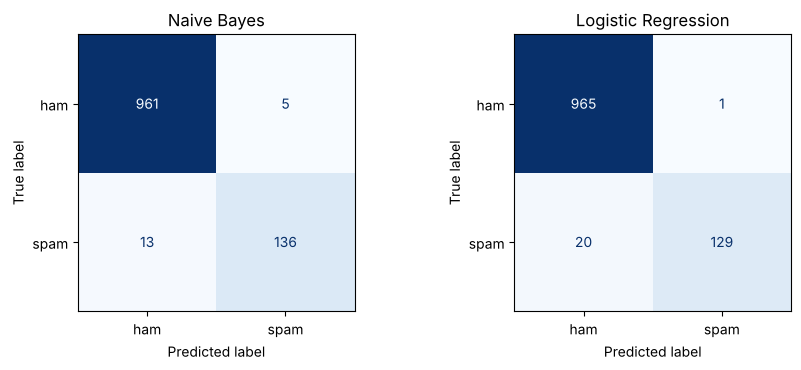

In [16]:
# Task 18 - train Logistic Regression on Task A's vectorized features
lr = LogisticRegression(max_iter=1000)          # default C = 1.0 (L2 regularisation)
lr.fit(X_train_vec, y_train)                    # exactly the same X_train_vec that Naive Bayes used
y_pred_lr = lr.predict(X_test_vec)

acc_lr = accuracy_score(y_test, y_pred_lr)
prec_lr = precision_score(y_test, y_pred_lr)
rec_lr = recall_score(y_test, y_pred_lr)
f1_lr = f1_score(y_test, y_pred_lr)
cm_lr = confusion_matrix(y_test, y_pred_lr)
tn_lr, fp_lr, fn_lr, tp_lr = cm_lr.ravel()

nb_vs_lr = pd.DataFrame({"Naive Bayes": [acc_a, prec_a, rec_a, f1_a],
                         "Logistic Regression": [acc_lr, prec_lr, rec_lr, f1_lr]},
                        index=["Accuracy", "Precision", "Recall", "F1-score"]).round(4)
display(nb_vs_lr)
print(f"Naive Bayes        : FP={fp_a:>2}  FN={fn_a:>2}  total errors={fp_a + fn_a}")
print(f"Logistic Regression: FP={fp_lr:>2}  FN={fn_lr:>2}  total errors={fp_lr + fn_lr}")

fig, axes = plt.subplots(1, 2, figsize=(9, 3.8))
ConfusionMatrixDisplay(cm_a, display_labels=["ham", "spam"]).plot(ax=axes[0], cmap="Blues", values_format="d", colorbar=False)
axes[0].set_title("Naive Bayes")
ConfusionMatrixDisplay(cm_lr, display_labels=["ham", "spam"]).plot(ax=axes[1], cmap="Blues", values_format="d", colorbar=False)
axes[1].set_title("Logistic Regression")
plt.tight_layout()
plt.show()

In [17]:
# Is the gap real? 5-fold CV on the TRAINING set only (vectorizer re-fitted inside each fold)
models = {
    "Naive Bayes (alpha=1)": MultinomialNB(),
    "Logistic Regression, C=1 (default)": LogisticRegression(max_iter=1000, C=1),
    "Logistic Regression, C=10": LogisticRegression(max_iter=1000, C=10),
    "Logistic Regression, C=100": LogisticRegression(max_iter=1000, C=100),
}
rows = []
for name, model in models.items():
    res = cross_validate(make_pipeline(CountVectorizer(), model), X_train_txt, y_train, cv=cv5, scoring=["precision", "recall", "f1"])
    rows.append({"model": name, "CV precision": res["test_precision"].mean().round(4), "CV recall": res["test_recall"].mean().round(4),
                 "CV F1": res["test_f1"].mean().round(4), "F1 std": res["test_f1"].std().round(4)})
cv_models = pd.DataFrame(rows)
display(cv_models)

,model,CV precision,CV recall,CV F1,F1 std
0,Naive Bayes (alpha=1),0.9811,0.9297,0.9545,0.0059
1,"Logistic Regression, C=1 (default)",0.9798,0.8779,0.9257,0.0172
2,"Logistic Regression, C=10",0.9853,0.8879,0.9338,0.0156
3,"Logistic Regression, C=100",0.9836,0.8963,0.9378,0.0128


**Task 18 — Naive Bayes vs. Logistic Regression (Task A)**

| Metric | Naive Bayes | Logistic Regression |
|---|---|---|
| Accuracy | 0.9839 | 0.9812 |
| Precision | 0.9645 | 0.9923 |
| Recall | 0.9128 | 0.8658 |
| F1-score | 0.9379 | 0.9247 |

**Answer 18 (which wins, and does it match expectations):**
On the test set Naive Bayes wins on accuracy, recall and F1 (0.938 against 0.925), while Logistic Regression wins on precision (0.992 against 0.965): Logistic Regression made 1 false positive and 20 false negatives, Naive Bayes 5 and 13. The difference is small (18 against 21 errors out of 1,115 messages), but the cross-validation on the training set points the same way: F1 0.955 for Naive Bayes against 0.926 for Logistic Regression with its default regularisation, and Logistic Regression only reaches 0.938 even with the weaker regularisation C = 100, so the gap is not just a tuning accident. This surprised me a little, because I expected Logistic Regression to win: it does not assume that words are independent and can weigh correlated words properly. With only 4,457 training messages and 7,658 word features, however, Naive Bayes has very few quantities to estimate and tends to do well in that situation, while Logistic Regression has to learn a weight for every word and was more reluctant to flag borderline spam. Since I argued that a false positive is the worse mistake, Logistic Regression's higher precision is arguably the better profile for an SMS filter, so I would call the two models close and choose between them by the cost of each error type rather than by F1 alone.


---

## 10. Final Reflection & Conclusion

**Tasks**
19. Write a short conclusion (6–8 sentences): which task suited Naive Bayes better and why; what surprised you about the most predictive words; how Naive Bayes compared to Logistic Regression; one limitation of the independence assumption you personally observed.
20. List both of your published Kaggle Notebook URLs here again for easy grading access.

**Answer 19 — Conclusion:**
Naive Bayes suited Task A (spam) much better than Task B (sentiment): its F1 was 0.938 against 0.720, and it removed 88% of the errors of a majority-class baseline compared with 54%. The reason is that spam is identified by a small set of almost class-exclusive trigger words that behave roughly independently, while the sentiment of a tweet depends on how words combine. What surprised me about the predictive words is how little they look like "meaning": the strongest ham words were pronouns and fillers (*he*, *she*, *later*) plus HTML leftovers (*gt*, *lt*, *amp*), *free*, my first guess for the top spam word, has a log-ratio of only 2.22, and on tweets some of the strongest positive words were names and brand terms (*lauren*, *bluemanity*, *admiral*) while the negative side was dominated by delay vocabulary (*hrs*, *hours*, *hold*). On the same features, Naive Bayes was slightly better than Logistic Regression on F1 (0.938 against 0.925) with higher recall, and Logistic Regression was more precise (0.992 against 0.965), so the two are close and I would choose by the cost of errors. The limitation of the independence assumption that I observed myself is that every word is scored on its own: positive tweets containing a negation word were found only 24.5% of the time against 64.0% for the others, and 59 of 219 mistakes on tweets were made with more than 99% confidence because the probabilities of many correlated words are multiplied as if they were independent. Practical lessons were to fit the vectorizer on training data only, to use word counts rather than TF-IDF with `MultinomialNB` (TF-IDF cut the spam recall from 0.93 to 0.67 in cross-validation), and to judge imbalanced data by precision and recall instead of accuracy. A last caveat is that 12% of the SMS test messages are copies of training messages, so the Task A scores are slightly optimistic.

**Answer 20 — Kaggle Notebook Links:**
- Task A: _______
- Task B: _______


---

## Submission Checklist

Before submitting, confirm you have:

- [x] Filled in the student-info block at the top (Name, Student ID, Section, GitHub, Kaggle, both datasets)
- [x] Section 1 — Problem Definition & Dataset Exploration (both datasets, neutral tweets dropped)
- [x] Section 2 — Task A Cleaning & Vectorization (fit on training data only)
- [x] Section 3 — Task A Model & Evaluation (all four metrics + confusion matrix + precision/recall argument)
- [x] Section 4 — Task A Word Interpretation (top words + your own test messages)
- [x] Section 5 — Task A Kaggle Notebook published and linked
- [x] Section 6 — Task B Cleaning & Vectorization (cleaning choices justified)
- [x] Section 7 — Task B Model & Evaluation (all four metrics + independence-assumption discussion)
- [x] Section 8 — Task B Kaggle Notebook published and linked
- [x] Section 9 — Cross-Task Comparison & vs. Logistic Regression
- [x] Section 10 — Final Reflection & Conclusion (both Kaggle links listed again)
- [x] Notebook exported/shared as a single Colab (.ipynb) file — no other files submitted